<a href="https://colab.research.google.com/github/JonathanDP02/244107020197-Pembelajaran-Mesin/blob/main/JS13_Implementasi_dataset_Praktikum_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
try:
    from google.colab import files
    uploaded = files.upload()
    nama_file = next(iter(uploaded))
except ImportError:
    nama_file = "Sleep_health_and_lifestyle_dataset(1).csv"

data = pd.read_csv(nama_file)
print("Ukuran dataset:", data.shape)
display(data.head())

Saving Sleep_health_and_lifestyle_dataset(1).csv to Sleep_health_and_lifestyle_dataset(1) (1).csv
Ukuran dataset: (374, 13)


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [3]:
data = data.copy()
data["Sleep Disorder"] = data["Sleep Disorder"].fillna("No Disorder")

# Pisahkan tekanan darah menjadi dua fitur numerik
bp = data["Blood Pressure"].str.extract(r"(?P<Systolic>\d+)\s*/\s*(?P<Diastolic>\d+)")
data["Systolic"] = pd.to_numeric(bp["Systolic"], errors="coerce")
data["Diastolic"] = pd.to_numeric(bp["Diastolic"], errors="coerce")

# Label biner: 0 = No Disorder, 1 = ada gangguan tidur
data["Target"] = (data["Sleep Disorder"] != "No Disorder").astype(int)

# Hapus ID, kolom teks tekanan darah, dan label asli
data = data.drop(columns=["Person ID", "Blood Pressure", "Sleep Disorder"])

# One-hot encoding fitur kategorikal
data = pd.get_dummies(data, columns=["Gender", "Occupation", "BMI Category"], dtype=int)

# Pastikan tidak ada nilai kosong pada fitur
data = data.dropna().reset_index(drop=True)

print("Ukuran data setelah preprocessing:", data.shape)
print(data["Target"].value_counts().rename(index={0:"No Disorder", 1:"Sleep Disorder"}))
display(data.head())

Ukuran data setelah preprocessing: (374, 27)
Target
No Disorder       219
Sleep Disorder    155
Name: count, dtype: int64


,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Systolic,Diastolic,Target,...,Occupation_Nurse,Occupation_Sales Representative,Occupation_Salesperson,Occupation_Scientist,Occupation_Software Engineer,Occupation_Teacher,BMI Category_Normal,BMI Category_Normal Weight,BMI Category_Obese,BMI Category_Overweight
0,27,6.1,6,42,6,77,4200,126,83,0,...,0,0,0,0,1,0,0,0,0,1
1,28,6.2,6,60,8,75,10000,125,80,0,...,0,0,0,0,0,0,1,0,0,0
2,28,6.2,6,60,8,75,10000,125,80,0,...,0,0,0,0,0,0,1,0,0,0
3,28,5.9,4,30,8,85,3000,140,90,1,...,0,1,0,0,0,0,0,0,1,0
4,28,5.9,4,30,8,85,3000,140,90,1,...,0,1,0,0,0,0,0,0,1,0


In [4]:
X = data.drop(columns=["Target"]).to_numpy(dtype=float)
y = data["Target"].to_numpy(dtype=float).reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (299, 26) | X_test: (75, 26)
y_train: (299, 1) | y_test: (75, 1)


In [5]:
def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(a):
    return a * (1 - a)

def relu(x):
    return np.maximum(0, x)

def relu_derivative(z):
    return (z > 0).astype(float)

def train_ann_manual(X, y, hidden_size=2, activation="sigmoid",
                     lr=0.01, epochs=3000, seed=42):
    rng = np.random.default_rng(seed)
    input_size = X.shape[1]
    output_size = 1

    W1 = rng.normal(0, 0.1, (input_size, hidden_size))
    b1 = np.zeros((1, hidden_size))
    W2 = rng.normal(0, 0.1, (hidden_size, output_size))
    b2 = np.zeros((1, output_size))

    losses = []
    n = X.shape[0]

    for epoch in range(epochs):
        # Forward pass
        z1 = X @ W1 + b1
        if activation == "relu":
            a1 = relu(z1)
        else:
            a1 = sigmoid(z1)

        z2 = a1 @ W2 + b2
        a2 = sigmoid(z2)

        # Binary cross-entropy loss
        eps = 1e-8
        loss = -np.mean(y * np.log(a2 + eps) + (1-y) * np.log(1-a2 + eps))
        losses.append(loss)

        # Backpropagation untuk sigmoid output + binary cross entropy
        dz2 = (a2 - y) / n
        dW2 = a1.T @ dz2
        db2 = np.sum(dz2, axis=0, keepdims=True)

        da1 = dz2 @ W2.T
        if activation == "relu":
            dz1 = da1 * relu_derivative(z1)
        else:
            dz1 = da1 * sigmoid_derivative(a1)

        dW1 = X.T @ dz1
        db1 = np.sum(dz1, axis=0, keepdims=True)

        # Update bobot
        W1 -= lr * dW1
        b1 -= lr * db1
        W2 -= lr * dW2
        b2 -= lr * db2

        if epoch % 500 == 0:
            print(f"Epoch {epoch}, Loss: {loss:.5f}")

    params = (W1, b1, W2, b2)
    return params, losses

def predict_ann_manual(X, params, activation="sigmoid"):
    W1, b1, W2, b2 = params
    z1 = X @ W1 + b1
    a1 = relu(z1) if activation == "relu" else sigmoid(z1)
    probabilities = sigmoid(a1 @ W2 + b2)
    return (probabilities >= 0.5).astype(int)

In [6]:
params_2_sigmoid, loss_2_sigmoid = train_ann_manual(
    X_train, y_train, hidden_size=2, activation="sigmoid",
    lr=0.01, epochs=3000, seed=42
)

y_pred_2_sigmoid = predict_ann_manual(X_test, params_2_sigmoid, "sigmoid")
acc_2_sigmoid = accuracy_score(y_test, y_pred_2_sigmoid)

print(f"Akurasi 2 neuron Sigmoid: {acc_2_sigmoid * 100:.2f}%")
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_2_sigmoid))
print(classification_report(y_test, y_pred_2_sigmoid, target_names=["No Disorder", "Sleep Disorder"], zero_division=0))

Epoch 0, Loss: 0.68778
Epoch 500, Loss: 0.65624
Epoch 1000, Loss: 0.57967
Epoch 1500, Loss: 0.47502
Epoch 2000, Loss: 0.39712
Epoch 2500, Loss: 0.34767
Akurasi 2 neuron Sigmoid: 89.33%
Confusion matrix:
[[38  6]
 [ 2 29]]
                precision    recall  f1-score   support

   No Disorder       0.95      0.86      0.90        44
Sleep Disorder       0.83      0.94      0.88        31

      accuracy                           0.89        75
     macro avg       0.89      0.90      0.89        75
  weighted avg       0.90      0.89      0.89        75



In [7]:
params_3_sigmoid, loss_3_sigmoid = train_ann_manual(
    X_train, y_train, hidden_size=3, activation="sigmoid",
    lr=0.01, epochs=3000, seed=42
)

y_pred_3_sigmoid = predict_ann_manual(X_test, params_3_sigmoid, "sigmoid")
acc_3_sigmoid = accuracy_score(y_test, y_pred_3_sigmoid)

print(f"Akurasi 3 neuron Sigmoid: {acc_3_sigmoid * 100:.2f}%")
print("Loss akhir 2 neuron:", loss_2_sigmoid[-1])
print("Loss akhir 3 neuron:", loss_3_sigmoid[-1])

Epoch 0, Loss: 0.69709
Epoch 500, Loss: 0.67822
Epoch 1000, Loss: 0.66420
Epoch 1500, Loss: 0.59383
Epoch 2000, Loss: 0.45234
Epoch 2500, Loss: 0.34817
Akurasi 3 neuron Sigmoid: 89.33%
Loss akhir 2 neuron: 0.31636726383379254
Loss akhir 3 neuron: 0.2978673858113572


In [8]:
params_3_relu, loss_3_relu = train_ann_manual(
    X_train, y_train, hidden_size=3, activation="relu",
    lr=0.01, epochs=3000, seed=42
)

y_pred_3_relu = predict_ann_manual(X_test, params_3_relu, "relu")
acc_3_relu = accuracy_score(y_test, y_pred_3_relu)

print(f"Akurasi 3 neuron ReLU: {acc_3_relu * 100:.2f}%")
print("Loss akhir 3 neuron ReLU:", loss_3_relu[-1])
print(classification_report(y_test, y_pred_3_relu, target_names=["No Disorder", "Sleep Disorder"], zero_division=0))

Epoch 0, Loss: 0.69507
Epoch 500, Loss: 0.55834
Epoch 1000, Loss: 0.35387
Epoch 1500, Loss: 0.29208
Epoch 2000, Loss: 0.26502
Epoch 2500, Loss: 0.25080
Akurasi 3 neuron ReLU: 89.33%
Loss akhir 3 neuron ReLU: 0.24261280878518976
                precision    recall  f1-score   support

   No Disorder       0.95      0.86      0.90        44
Sleep Disorder       0.83      0.94      0.88        31

      accuracy                           0.89        75
     macro avg       0.89      0.90      0.89        75
  weighted avg       0.90      0.89      0.89        75



,Konfigurasi,Loss akhir,Akurasi (%)
0,2 neuron Sigmoid,0.316367,89.333333
1,3 neuron Sigmoid,0.297867,89.333333
2,3 neuron ReLU,0.242613,89.333333


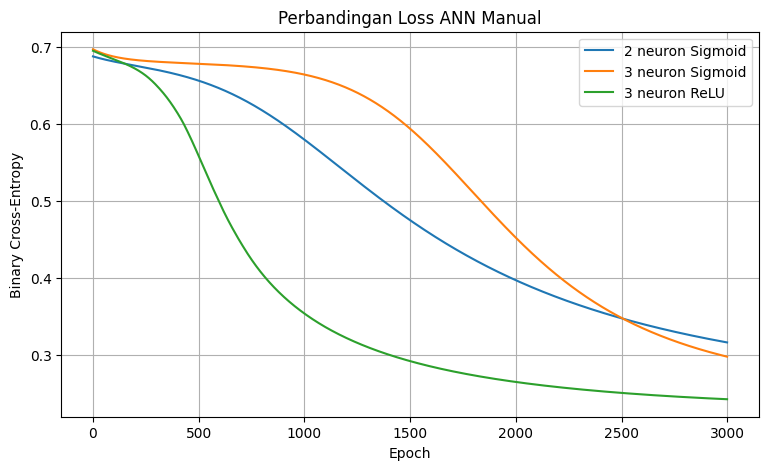

In [9]:
hasil = pd.DataFrame({
    "Konfigurasi": ["2 neuron Sigmoid", "3 neuron Sigmoid", "3 neuron ReLU"],
    "Loss akhir": [loss_2_sigmoid[-1], loss_3_sigmoid[-1], loss_3_relu[-1]],
    "Akurasi (%)": [acc_2_sigmoid*100, acc_3_sigmoid*100, acc_3_relu*100]
})
display(hasil)

plt.figure(figsize=(9, 5))
plt.plot(loss_2_sigmoid, label="2 neuron Sigmoid")
plt.plot(loss_3_sigmoid, label="3 neuron Sigmoid")
plt.plot(loss_3_relu, label="3 neuron ReLU")
plt.title("Perbandingan Loss ANN Manual")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy")
plt.legend()
plt.grid(True)
plt.show()